# Trust After AI Failure: A Reproducibility and Measurement-Sensitivity Analysis of Behavioural Reliance in Human–AI Interaction

**Project 7 · Ctrl+Alt+Delete · MSc Data Science · University of Europe for Applied Sciences, Germany**  
Target journal: *Computers in Human Behavior*.

**Research background.** Human–AI collaboration requires distinguishing reported trust from the extent to which users incorporate advice into their decisions. An observed reliance trajectory can depend on both behaviour and measurement implementation.

**Research problem and objective.** This secondary-data study examines whether conclusions about post-error behavioural reliance are sensitive to the Weight of Advice (WoA) formula, undefined ratios and analytical sample selection. It is a reproducibility and measurement-sensitivity analysis of an existing experiment; no new participants or interventions are introduced.

**Research questions.** The analysis addresses measurement sensitivity and reliance trajectories across four rounds and numeric conditions. Questions concerning perceived trust, literacy and interpretability are retained but remain gated by missing measurement documentation. The full, unchanged questions are stated in Section A.

**Dataset and source.** The empirical source is the supplied `Dataset_TrustCalibration.csv`, associated with Ouyang, Jahng and Woo (2026), Mendeley Data Version 1, DOI [10.17632/5w56cp2ftr.1](https://doi.org/10.17632/5w56cp2ftr.1). The loader reports its exact checksum, dimensions and record counts. Each row links its own four rounds; row ordinals are analytical record keys and do not establish unique participants.

**Analytical methodology.** The notebook audits published and independently derived WoA, estimates a saturated condition-by-round mean model with record-clustered covariance, and applies Holm correction to three planned differences in changes. Bootstrap intervals, paired-change tests, an alternative repeated-record model and prespecified sensitivity comparisons assess robustness. All statistical procedures are unchanged from the preceding executed analysis.

**Main findings.** Formula-based recalculation materially changes the exported late-round pattern. None of the three primary recalculated between-condition change contrasts meets the Holm-adjusted .05 criterion. This is not evidence of equivalence. Numerical estimates, intervals and p-values are generated by the executed cells and interpreted in Sections L–M.

**Limitations.** Numeric condition-to-treatment mapping, questionnaire scoring and timing, and complete stimulus ages and identifiers remain unresolved. The source paper contains inconsistent error-round wording. Participant uniqueness cannot be independently verified, and round changes confound stimulus, time and error history. Accuracy, appropriate reliance and questionnaire-composite analyses are therefore not inferred. Professor acceptance of the departure from the catalogue's three-intervention design remains undocumented. No publication-readiness claim is made.

**Reproducibility instructions.** Unzip the complete package and run the notebook from beginning to end using the documented dependencies. The unchanged CSV is in `data/`; alternatively place it beside the notebook. No network access is required during analysis. Sections H–K document blocked analyses, and the integrity/export section regenerates reports, tables, figures and the execution manifest. The README also supplies a socket-free execution option and archive-generation instructions.


## A. Research rationale, questions and evidential boundaries

The original study links explanations, reported trust and behavioral reliance following an AI error. A reliance measure can change because of behavior or because of computation. We examine the sensitivity of the reported trajectory to the paper-defined formula, undefined ratios and analytical sample selection. This is a reproducibility contribution; independent theoretical novelty has not been established.

**RQ1:** How sensitive are condition-specific reliance trajectories to WoA calculation and undefined-value handling?  
**RQ2:** After consistent preprocessing, how does reliance vary across four rounds and numeric conditions?  
**RQ3:** How is perceived trust associated with subsequent reliance? **Gated: scoring and timing unresolved.**  
**RQ4:** Exploratorily, do literacy and interpretability relate to post-error adjustment differently by condition? **Gated: item mapping/scoring unresolved.**

We use two-sided tests and no novel directional hypotheses: the published direction has already been observed, and condition labels remain unverified. The primary inferential family is the three between-code differences in round changes R3−R1, R4−R1 and R4−R3, with Holm adjustment. This analysis specification is written after the earlier audit, not prospectively preregistered. Sensitivity analyses assess stability, not independent replication samples.

**Unit and linkage.** A source row contains its own four rounds. `record_id` is the CSV data-row ordinal, **not an invented or verified participant ID**. Clustered inference assumes independent records; we cannot establish that distinct rows are distinct people. Exact duplicate sensitivity addresses one observable ambiguity, not all possible repeat participation.

**Causal limits.** The paper reports random assignment, but numeric assignment and protocol implementation cannot be independently checked from this export. All records experience the same round sequence. Round changes confound time, stimulus and error history; there is no contemporaneous no-error control. Therefore this notebook describes post-error trajectories, not an identified causal effect of error exposure. WoA is reliance, not appropriate reliance, overreliance or decision accuracy.

**Sources and page locators.** Ouyang, Jahng & Woo (2026), DOI [10.1080/10447318.2026.2705163](https://doi.org/10.1080/10447318.2026.2705163), printed pp. 6–9 (procedure/formula/missingness), pp. 10–13 (analyses), Appendix A p. 19 (items/PT5 reversal); publisher cover adds one to PDF page numbers. Dataset [10.17632/5w56cp2ftr.1](https://doi.org/10.17632/5w56cp2ftr.1), V1, CC BY 4.0. Graf (2025), [10.1016/j.chb.2025.108736](https://doi.org/10.1016/j.chb.2025.108736), pp. 4–7 and 10–11. Catalogue: Project 7 and common checkpoints. The preceding research-design audit is documented in the project conversation; a separately named audit attachment was not supplied. No original article PDFs are redistributed in this package.

In [2]:
from pathlib import Path
import os, sys, json, hashlib, platform, warnings, importlib.metadata as metadata
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests
from IPython.display import display, Markdown

SEED = 20261109
BOOTSTRAPS = 4000
TOL = 1e-7  # published decimals have about nine digits
SMALL_GAP = 2  # sensitivity: at least two years; not a validity threshold
BASE = Path.cwd().resolve()
OUTPUT = BASE / 'outputs'
TABLES = OUTPUT / 'tables'
FIGURES = OUTPUT / 'figures'
for directory in (TABLES, FIGURES):
    directory.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 120, 'savefig.dpi': 200, 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'pdf.fonttype': 42, 'axes.titleweight': 'bold'})
COLORS = {0: '#23688c', 1: '#b74e23'}
def save_table(frame, name):
    frame.to_csv(TABLES / (name + '.csv'), index=False)
    return frame
def finish_figure(fig, name, caption):
    fig.text(.01, .005, caption, ha='left', va='bottom', fontsize=8, wrap=True)
    fig.tight_layout(rect=(0, .07, 1, 1))
    for extension in ['png', 'pdf']:
        fig.savefig(FIGURES / f'{name}.{extension}', bbox_inches='tight')
    plt.show()
    plt.close(fig)
def md_table(frame, decimals=4):
    def cell(value):
        if pd.isna(value): return 'NA'
        if isinstance(value, (float, np.floating)): return f'{value:.{decimals}g}'
        return str(value).replace('|', '/').replace('\n', ' ')
    return ('| ' + ' | '.join(map(str, frame.columns)) + ' |\n' +
            '| ' + ' | '.join(['---'] * len(frame.columns)) + ' |\n' +
            '\n'.join('| ' + ' | '.join(cell(v) for v in row) + ' |'
                      for row in frame.itertuples(index=False, name=None)))
def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()
packages = {name: metadata.version(name) for name in
            ['numpy', 'pandas', 'matplotlib', 'scipy', 'statsmodels', 'nbformat', 'nbclient', 'ipykernel']}
display(pd.Series(packages, name='version').to_frame())
print('Working directory:', BASE)

,version
numpy,2.4.6
pandas,3.0.3
matplotlib,3.10.9
scipy,1.18.1
statsmodels,0.15.0
nbformat,5.11.1
nbclient,0.11.0
ipykernel,7.3.0


Working directory: /Users/keshavreddy/Downloads/Trust_After_AI_Failure


## B. Load and validate the actual source

The loader checks explicit locations relative to the current working directory, or an optional `TRUST_CSV` environment variable. Multiple differing files cause an error. The exact source checksum is recorded. Original strings, including `#DIV/0!`, are preserved in `raw`; numeric conversions occur in a separate copy. First/last records omit the feedback text from display, but the original data remain preserved. Blank and nonnumeric ratio cells are counted separately.

In [3]:
CSV_NAME = 'Dataset_TrustCalibration.csv'
override = os.environ.get('TRUST_CSV')
if override:
    candidates = [Path(override).expanduser().resolve()]
else:
    candidates = [BASE / 'data' / CSV_NAME, BASE / CSV_NAME,
                  BASE / 'upload' / CSV_NAME, BASE.parent / 'upload' / CSV_NAME]
candidates = list(dict.fromkeys(p.resolve() for p in candidates if p.is_file()))
if not candidates:
    raise FileNotFoundError('Place the actual Dataset_TrustCalibration.csv in data/ or beside the notebook, or set TRUST_CSV.')
if len({sha256(p) for p in candidates}) != 1:
    raise ValueError('Different CSV versions found. Set TRUST_CSV to the intended exact file.')
DATA_PATH = candidates[0]
SOURCE_SHA256 = sha256(DATA_PATH)
raw = pd.read_csv(DATA_PATH, dtype=str, keep_default_na=False)
source_snapshot = raw.copy(deep=True)
required = ['Condition'] + [f'R{r}_{s}' for r in range(1, 5) for s in 'IAF'] + [f'WoA_R{r}' for r in range(1, 5)]
missing_columns = sorted(set(required) - set(raw))
if missing_columns: raise ValueError(f'Missing required columns: {missing_columns}')
print('Source:', DATA_PATH)
print('SHA256:', SOURCE_SHA256)
print('Observed shape:', raw.shape)
print('Observed columns:', list(raw))
display(raw.drop(columns=['WoA_R1.1'], errors='ignore').head(3).T)
display(raw.drop(columns=['WoA_R1.1'], errors='ignore').tail(3).T)
quality = pd.DataFrame({'column': raw.columns, 'raw_dtype': raw.dtypes.astype(str).values,
                        'blank': [raw[c].str.strip().eq('').sum() for c in raw],
                        'division_error': [raw[c].eq('#DIV/0!').sum() for c in raw],
                        'nonblank_unique': [raw.loc[raw[c].ne(''), c].nunique() for c in raw]})
display(save_table(quality, 'raw_missingness_and_types'))
print('Conditions:', raw.Condition.value_counts(dropna=False).to_dict())
duplicate_flags = raw.duplicated(keep='first')
duplicate_rows = pd.DataFrame({'record_id': np.flatnonzero(raw.duplicated(keep=False)) + 1})
duplicate_rows['csv_line'] = duplicate_rows.record_id + 1
display(save_table(duplicate_rows, 'exact_duplicate_records'))
print('Extra exact duplicate rows:', int(duplicate_flags.sum()))

Source: /Users/keshavreddy/Downloads/Trust_After_AI_Failure/data/Dataset_TrustCalibration.csv
SHA256: 0ffa5341b5dec771d2e11169ff3bceb4c43306a83677f32d2f81d3a997ef696d
Observed shape: (412, 50)
Observed columns: ['Condition', 'Q1_1', 'Q1_2', 'Q1_3', 'Q1_4', 'Q2_1', 'Q2_2', 'Q2_3', 'Q2_4', 'Q2_5', 'Q2_6', 'Q2_7', 'Q2_8', 'Q2_9', 'Q2_10', 'Q2_11', 'Q2_12', 'Q2_13', 'Q2_14', 'Q2_15', 'Q2_16', 'Q2_17', 'Q2_18', 'R1_I', 'R1_A', 'R1_F', 'Q4_1', 'Q4_2', 'Q4_3', 'R2_I', 'R2_A', 'R2_F', 'R3_I', 'R3_A', 'R3_F', 'Q6_1', 'Q6_2', 'Q6_3', 'Q6_4', 'Q6_5', 'R4_I', 'R4_A', 'R4_F', 'WoA_R1', 'WoA_R2', 'WoA_R3', 'WoA_R4', 'Unnamed: 47', 'Unnamed: 48', 'WoA_R1.1']


,0,1,2
Condition,1,1,1
Q1_1,2,2,1
Q1_2,41~50,31~40,18~25
Q1_3,2,2,2
Q1_4,1,2,1
Q2_1,6,5,6
Q2_2,7,6,7
Q2_3,6,5,5
Q2_4,6,7,6
Q2_5,7,5,6


,409,410,411
Condition,0,0,0
Q1_1,2,2,1
Q1_2,41~50,18~25,26~30
Q1_3,1,3,1
Q1_4,2,2,2
Q2_1,3,7,3
Q2_2,4,7,2
Q2_3,5,7,2
Q2_4,5,7,2
Q2_5,5,6,2


,column,raw_dtype,blank,division_error,nonblank_unique
0,Condition,str,0,0,2
1,Q1_1,str,0,0,2
2,Q1_2,str,0,0,5
3,Q1_3,str,0,0,4
4,Q1_4,str,0,0,2
5,Q2_1,str,0,0,6
6,Q2_2,str,0,0,6
7,Q2_3,str,0,0,7
8,Q2_4,str,0,0,6
9,Q2_5,str,0,0,7


Conditions: {'1': 206, '0': 206}


,record_id,csv_line
0,40,41
1,41,42


Extra exact duplicate rows: 1


## C. Variable dictionary and mapping uncertainty

Dataset documentation establishes the questionnaire *families*, not the exact item-to-column order or scoring implementation. `Q1_3` is consistent with education through Table 1 count matching, but its coding remains inferred. Appendix A documents 18 literacy, three interpretability and five trust statements, with PT5 reversed; it does not establish whether the exported `Q6_5` is raw PT5. No composite is scored here. Numerical condition codes remain unlabelled.

In [4]:
def describe_column(c):
    if c == 'Condition': return ('Experimental group code', 'Grouping', 'PARTIALLY VERIFIED', '0/1 label mapping unavailable')
    if c == 'Q1_1': return ('Gender; documentation: 1 male, 2 female', 'Descriptive only', 'VERIFIED', 'Limited recorded categories')
    if c == 'Q1_2': return ('Age category', 'Descriptive only', 'VERIFIED', 'Categorical, not exact age')
    if c == 'Q1_3': return ('Education, inferred from Table 1 counts', 'Descriptive only', 'PARTIALLY VERIFIED', 'Numeric category codebook absent')
    if c == 'Q1_4': return ('AI-related job; documentation: 1 yes, 2 no', 'Descriptive only', 'VERIFIED', '')
    if c.startswith('Q2_'): return ('AI-literacy response family', 'Raw-item descriptions', 'PARTIALLY VERIFIED', 'Individual item mapping and composite scoring unresolved')
    if c.startswith('Q4_'): return ('Perceived-interpretability response family', 'Raw-item descriptions', 'PARTIALLY VERIFIED', 'Mapping, timing and published descriptives unresolved')
    if c.startswith('Q6_'): return ('Perceived-trust response family', 'Raw-item descriptions', 'PARTIALLY VERIFIED', 'Mapping, timing and PT5 export status unresolved')
    if c == 'WoA_R1.1': return ('Chinese free-text feedback', 'Excluded from numeric analysis', 'VERIFIED', 'Misleading heading; nonrandom availability')
    if c.startswith('WoA_R'): return ('Exported WoA value', 'Sensitivity comparison', 'PARTIALLY VERIFIED', 'Ratio errors, zeros and R4 discrepancy')
    if c.startswith('Unnamed:'): return ('Empty export column if validated empty', 'No analytical role', 'VERIFIED' if raw[c].eq('').all() else 'UNVERIFIED', '')
    if c.startswith('R') and c[-2:] in ['_I', '_A', '_F']:
        meanings = {'I': 'Initial age estimate', 'A': 'AI age prediction (not ground truth)', 'F': 'Final age judgment'}
        return (meanings[c[-1]], 'WoA input', 'VERIFIED', 'No stimulus identifier or true-age field')
    return ('Undocumented', 'Unused', 'UNVERIFIED', 'Needs codebook')
dictionary = pd.DataFrame([{'column': c, 'storage_type': str(raw[c].dtype),
                           **dict(zip(['meaning','role','verification_status','uncertainty'], describe_column(c)))} for c in raw])
display(save_table(dictionary, 'variable_dictionary'))

,column,storage_type,meaning,role,verification_status,uncertainty
0,Condition,str,Experimental group code,Grouping,PARTIALLY VERIFIED,0/1 label mapping unavailable
1,Q1_1,str,"Gender; documentation: 1 male, 2 female",Descriptive only,VERIFIED,Limited recorded categories
2,Q1_2,str,Age category,Descriptive only,VERIFIED,"Categorical, not exact age"
3,Q1_3,str,"Education, inferred from Table 1 counts",Descriptive only,PARTIALLY VERIFIED,Numeric category codebook absent
4,Q1_4,str,"AI-related job; documentation: 1 yes, 2 no",Descriptive only,VERIFIED,
5,Q2_1,str,AI-literacy response family,Raw-item descriptions,PARTIALLY VERIFIED,Individual item mapping and composite scoring ...
6,Q2_2,str,AI-literacy response family,Raw-item descriptions,PARTIALLY VERIFIED,Individual item mapping and composite scoring ...
7,Q2_3,str,AI-literacy response family,Raw-item descriptions,PARTIALLY VERIFIED,Individual item mapping and composite scoring ...
8,Q2_4,str,AI-literacy response family,Raw-item descriptions,PARTIALLY VERIFIED,Individual item mapping and composite scoring ...
9,Q2_5,str,AI-literacy response family,Raw-item descriptions,PARTIALLY VERIFIED,Individual item mapping and composite scoring ...


## D. Analytical copy and record keys

`record_id=1` denotes the first CSV data row and `csv_line=2` includes the header. These are transparent source locators, not human identities. Duplicate records are retained in the primary analysis. Empty export columns and feedback text are excluded from the numeric analytical view; the complete source remains in `raw` and the bundled CSV. Unexpected numeric source values cause an explicit failure rather than silent coercion. Unusual valid estimates are not deleted.

In [5]:
analysis = raw.copy(deep=True)
analysis.insert(0, 'record_id', np.arange(1, len(raw) + 1))
analysis.insert(1, 'csv_line', analysis.record_id + 1)
analysis['duplicate_extra'] = duplicate_flags.to_numpy()
for c in ['Condition'] + [f'R{r}_{s}' for r in range(1, 5) for s in 'IAF']:
    converted = pd.to_numeric(raw[c], errors='coerce')
    if converted.isna().any() or not np.isfinite(converted).all():
        raise ValueError(f'Invalid or missing required numeric input in {c}')
    analysis[c] = converted
if not analysis.Condition.isin([0, 1]).all(): raise ValueError('Unexpected condition code')
analysis.Condition = analysis.Condition.astype(int)
for c in [x for x in raw if x.startswith(('Q2_', 'Q4_', 'Q6_'))]:
    analysis[c] = pd.to_numeric(raw[c], errors='coerce')
    if analysis[c].isna().any() or not analysis[c].between(1, 7).all():
        raise ValueError(f'Unexpected questionnaire response in {c}')
empty_columns = [c for c in raw if c.startswith('Unnamed:') and raw[c].eq('').all()]
feedback_summary = analysis.groupby('Condition')['WoA_R1.1'].apply(lambda x: x.str.strip().ne('').sum()).rename('nonempty_feedback').reset_index()
save_table(feedback_summary, 'feedback_availability')
analytical_numeric = analysis.drop(columns=empty_columns + ['WoA_R1.1'], errors='ignore')
display(save_table(analysis[['Condition'] + [f'R{r}_{s}' for r in range(1,5) for s in 'IAF']].describe().T.rename_axis('variable').reset_index(), 'numeric_summary'))
save_table(analytical_numeric, 'record_level_analytical_copy')
print('Excluded from numeric view:', empty_columns + ['WoA_R1.1'])
display(feedback_summary)

,variable,count,mean,std,min,25%,50%,75%,max
0,Condition,412.0,0.500000,0.500608,0.0,0.0,0.5,1.0,1.0
1,R1_I,412.0,27.871359,3.898400,18.0,25.0,28.0,30.0,43.0
2,R1_A,412.0,23.000000,0.000000,23.0,23.0,23.0,23.0,23.0
3,R1_F,412.0,24.934466,2.378549,20.0,23.0,25.0,25.0,50.0
4,R2_I,412.0,45.912621,6.321641,28.0,42.0,45.0,50.0,68.0
5,R2_A,412.0,37.000000,0.000000,37.0,37.0,37.0,37.0,37.0
6,R2_F,412.0,42.148058,4.878068,34.0,40.0,40.0,45.0,65.0
7,R3_I,412.0,35.745146,5.833922,20.0,32.0,35.0,40.0,56.0
8,R3_A,412.0,28.000000,0.000000,28.0,28.0,28.0,28.0,28.0
9,R3_F,412.0,33.344660,4.759689,22.0,30.0,32.0,35.0,51.0


Excluded from numeric view: ['Unnamed: 47', 'Unnamed: 48', 'WoA_R1.1']


,Condition,nonempty_feedback
0,0,0
1,1,200


## E. Independently derive and audit WoA

Ouyang et al., printed p. 7, defines **WoA=(F−I)/(A−I)**, missing when A=I, retaining finite values outside [0,1]. Published columns remain intact. We distinguish raw-export numeric values from published values masked by the paper's denominator rule. This separates numerical-formula sensitivity from undefined-value handling. Our derivatives are independently derived analytical variables, not the authors' corrected data.

In [6]:
long_parts = []
for r in range(1, 5):
    initial, advice, final = (analysis[f'R{r}_{s}'].astype(float) for s in 'IAF')
    gap = advice - initial
    calculated = np.divide(final-initial, gap, out=np.full(len(raw), np.nan), where=gap.ne(0))
    published = pd.to_numeric(raw[f'WoA_R{r}'], errors='coerce').astype(float)
    published = published.where(np.isfinite(published))
    analysis[f'woa_recalculated_R{r}'] = calculated
    part = pd.DataFrame({'record_id': analysis.record_id, 'csv_line': analysis.csv_line,
                         'condition': analysis.Condition, 'round': r, 'initial': initial,
                         'advice': advice, 'final': final, 'gap': gap,
                         'duplicate_extra': analysis.duplicate_extra,
                         'published_token': raw[f'WoA_R{r}'], 'published_export': published,
                         'published_masked': published.where(gap.ne(0)),
                         'recalculated': calculated})
    part['undefined'] = gap.eq(0)
    part['comparable'] = part.recalculated.notna() & part.published_export.notna()
    part['discrepancy'] = part.comparable & ((part.published_export-part.recalculated).abs() > TOL)
    part['outside_unit_interval'] = part.recalculated.notna() & ~part.recalculated.between(0,1)
    part['complement_match'] = part.comparable & ((part.published_export + part.recalculated - 1).abs() <= TOL)
    long_parts.append(part)
long = pd.concat(long_parts, ignore_index=True).sort_values(['record_id','round']).reset_index(drop=True)
audit = long.groupby(['condition','round']).agg(records=('record_id','size'), undefined=('undefined','sum'),
        published_numeric=('published_export','count'), recalculated_finite=('recalculated','count'),
        comparable=('comparable','sum'), disagreements=('discrepancy','sum'),
        complement_matches=('complement_match','sum'), outside_0_1=('outside_unit_interval','sum')).reset_index()
display(save_table(audit, 'woa_audit_by_condition_round'))
save_table(long, 'round_level_analytical_data')
save_table(analysis.drop(columns=empty_columns + ['WoA_R1.1']), 'record_level_analytical_copy')
examples = long.loc[long.discrepancy | long.undefined, ['record_id','csv_line','condition','round','initial','advice','final','published_token','recalculated','complement_match']]
save_table(examples, 'woa_discrepancy_and_undefined_records')
display(examples.head(15))
r4c0 = long[(long.condition == 0) & (long['round'] == 4)]
r4_comparable = r4c0[r4c0.comparable]
display(Markdown(f'**Observed Round 4, code 0:** {len(r4_comparable)} comparable records; '
                 f'{int(r4_comparable.discrepancy.sum())} disagreements and '
                 f'{int(r4_comparable.complement_match.sum())} complement matches. '
                 'Matching .5 satisfies both formulas; complement matches and disagreements are different counts.'))
display(r4_comparable.loc[~r4_comparable.complement_match, ['record_id','csv_line','initial','advice','final','published_export','recalculated']])

,condition,round,records,undefined,published_numeric,recalculated_finite,comparable,disagreements,complement_matches,outside_0_1
0,0,1,206,9,197,197,197,0,27,1
1,0,2,206,2,204,204,204,0,8,7
2,0,3,206,6,200,200,200,0,16,12
3,0,4,206,4,202,202,202,173,201,18
4,1,1,206,7,205,199,199,0,22,1
5,1,2,206,3,205,203,203,0,15,8
6,1,3,206,7,205,199,199,0,21,11
7,1,4,206,4,206,202,202,0,35,21


,record_id,csv_line,condition,round,initial,advice,final,published_token,recalculated,complement_match
11,3,4,1,4,44.0,44.0,44.0,0,NaN,False
56,15,16,1,1,23.0,23.0,23.0,0,NaN,False
267,67,68,1,4,44.0,44.0,40.0,0,NaN,False
278,70,71,1,3,28.0,28.0,28.0,0,NaN,False
289,73,74,1,2,37.0,37.0,38.0,,NaN,False
346,87,88,1,3,28.0,28.0,28.0,,NaN,False
362,91,92,1,3,28.0,28.0,28.0,0,NaN,False
380,96,97,1,1,23.0,23.0,23.0,,NaN,False
387,97,98,1,4,44.0,44.0,44.0,0,NaN,False
426,107,108,1,3,28.0,28.0,28.0,0,NaN,False


**Observed Round 4, code 0:** 202 comparable records; 173 disagreements and 201 complement matches. Matching .5 satisfies both formulas; complement matches and disagreements are different counts.

,record_id,csv_line,initial,advice,final,published_export,recalculated
827,207,208,43.0,44.0,44.0,1.0,1.0


## F. Empirical distributions and trajectories

All displays use numeric conditions. No accuracy or appropriateness labels are attached. Figures show all finite WoA values; heavy tails and discrete masses matter. Trajectory intervals are pointwise 95% t intervals across records, not simultaneous intervals or paired-change tests. The primary contrasts below use covariance clustered within records. Individual repeated-trust trajectories cannot be plotted because they are not present.

,measure,condition,round,n_records,mean,median,sd,mean_ci_low,mean_ci_high,min,max
0,published_export,0,1,197,0.520873,0.583333,0.319457,0.475986,0.565759,-1.250000,1.000000
1,published_export,0,2,204,0.398262,0.400000,0.396652,0.343505,0.453019,-1.000000,3.000000
2,published_export,0,3,200,0.276675,0.267857,0.425333,0.217368,0.335983,-2.500000,1.666667
3,published_export,0,4,202,0.628151,0.545455,0.735088,0.526166,0.730135,-1.166667,6.000000
4,published_export,1,1,205,0.599289,0.600000,0.391025,0.545443,0.653136,-2.500000,1.000000
5,published_export,1,2,205,0.414490,0.444444,0.412732,0.357654,0.471326,-2.000000,2.000000
6,published_export,1,3,205,0.310718,0.300000,0.418219,0.253126,0.368309,-2.000000,1.000000
7,published_export,1,4,206,0.424628,0.458042,0.607165,0.341223,0.508033,-4.000000,3.000000
8,published_masked,0,1,197,0.520873,0.583333,0.319457,0.475986,0.565759,-1.250000,1.000000
9,published_masked,0,2,204,0.398262,0.400000,0.396652,0.343505,0.453019,-1.000000,3.000000


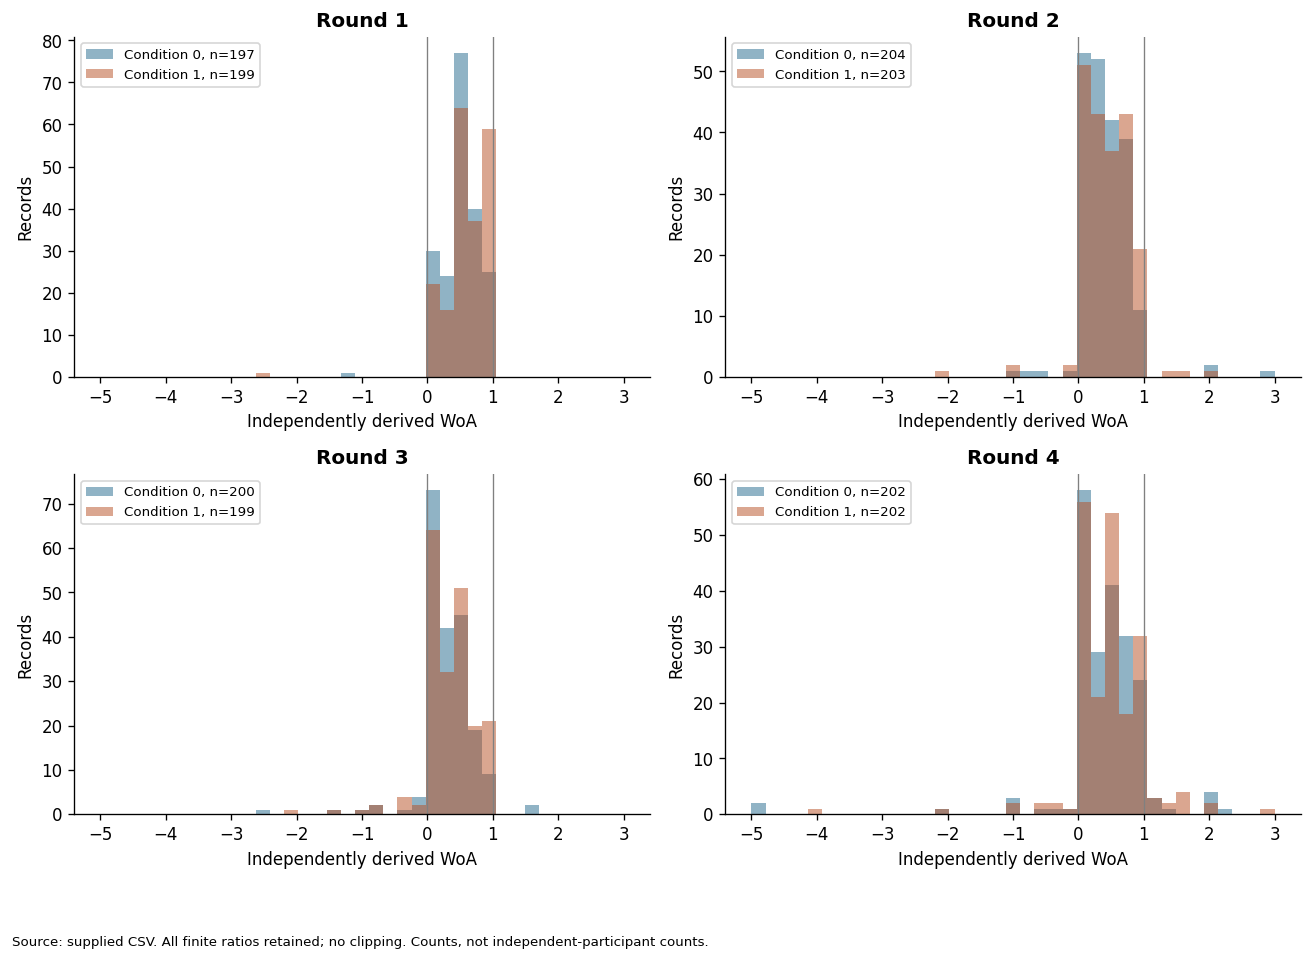

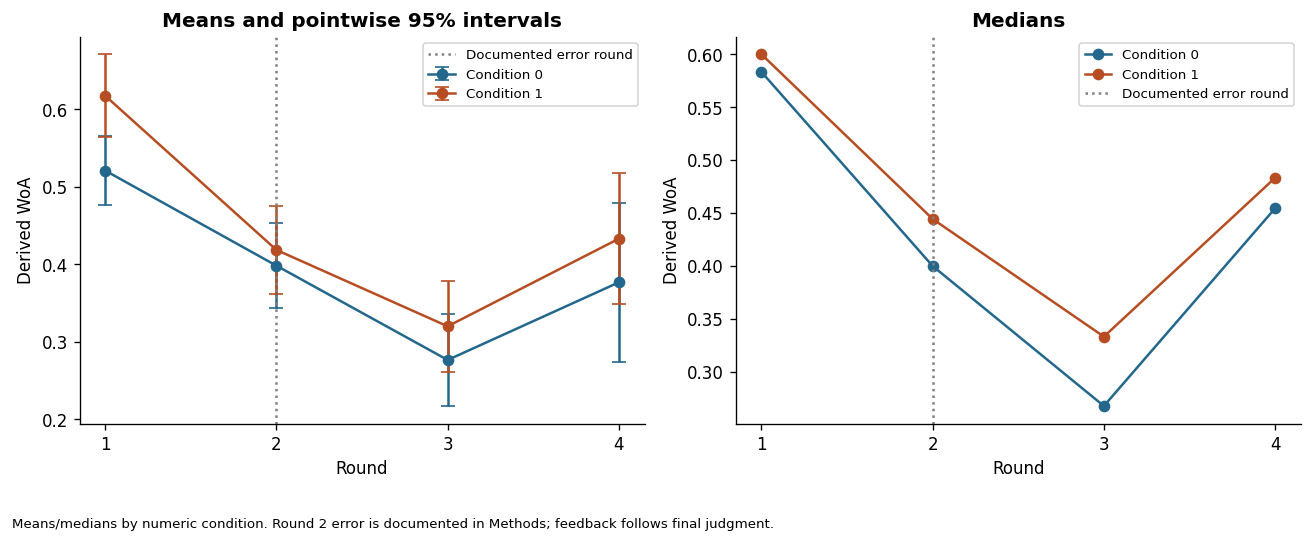

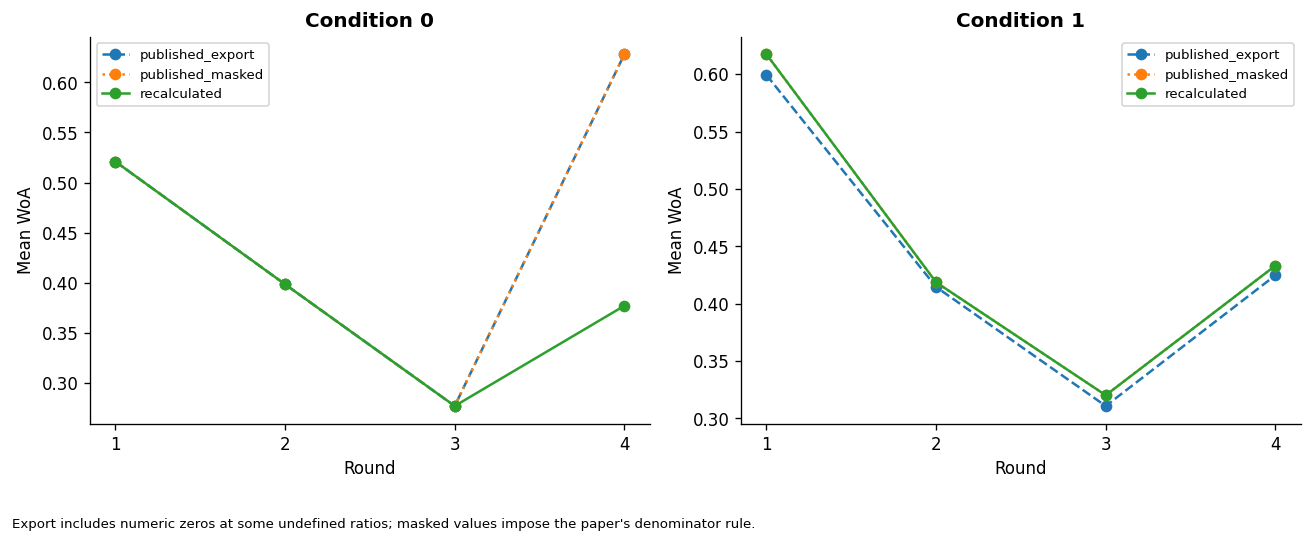

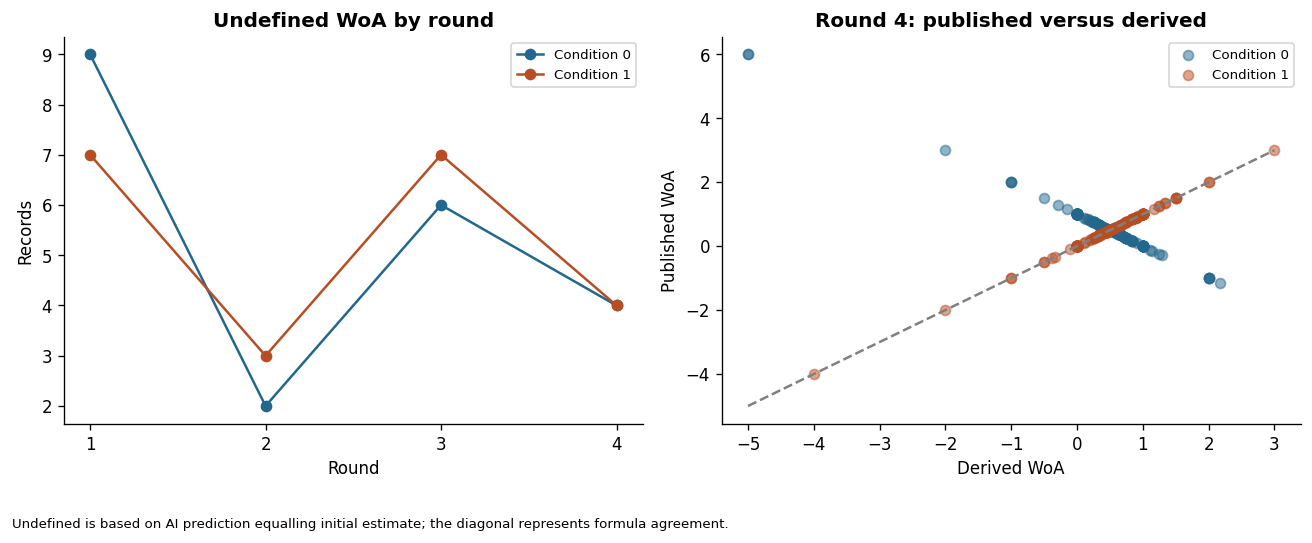

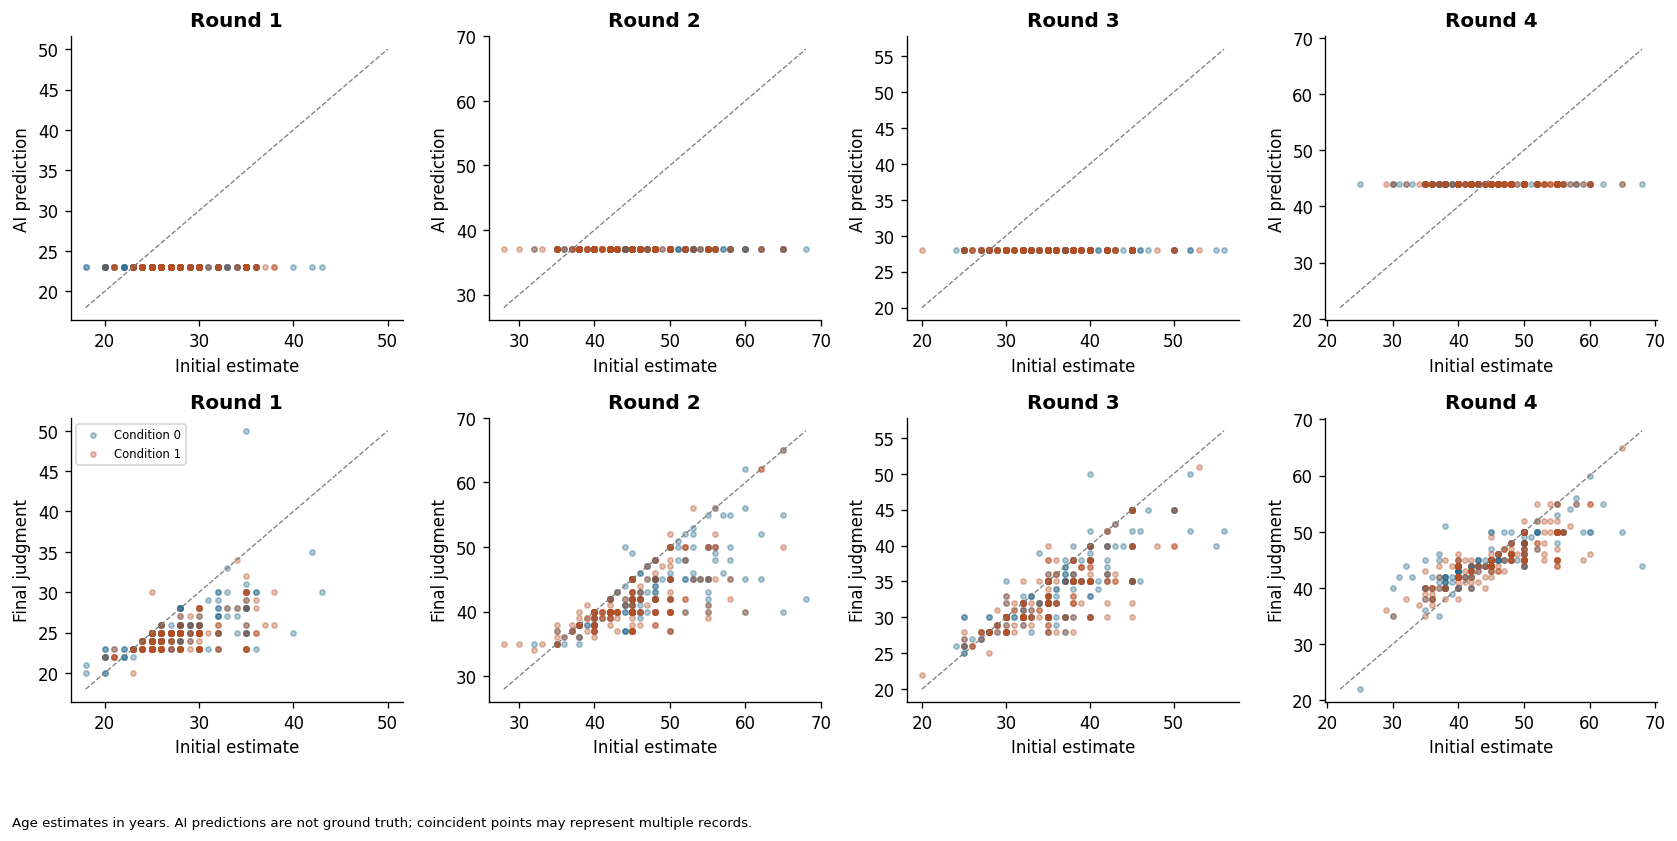

In [7]:
summaries = []
for measure in ['published_export','published_masked','recalculated']:
    for (g,r), sub in long.groupby(['condition','round']):
        x = sub[measure].dropna().to_numpy(); n = len(x)
        se = stats.sem(x) if n > 1 else np.nan
        half = stats.t.ppf(.975, n-1)*se if n > 1 else np.nan
        summaries.append({'measure':measure,'condition':g,'round':r,'n_records':n,
                          'mean':np.mean(x),'median':np.median(x),'sd':np.std(x,ddof=1),
                          'mean_ci_low':np.mean(x)-half,'mean_ci_high':np.mean(x)+half,
                          'min':np.min(x),'max':np.max(x)})
descriptives = pd.DataFrame(summaries)
display(save_table(descriptives, 'woa_descriptives'))
fig, axes = plt.subplots(2,2,figsize=(11,8))
for r,ax in zip(range(1,5), axes.flat):
    for g in [0,1]:
        x = long.loc[(long['round']==r)&(long.condition==g),'recalculated'].dropna()
        ax.hist(x, bins=np.linspace(long.recalculated.min(),long.recalculated.max(),38),
                alpha=.5, color=COLORS[g], label=f'Condition {g}, n={len(x)}')
    ax.axvline(0,color='gray',lw=.8);ax.axvline(1,color='gray',lw=.8)
    ax.set(title=f'Round {r}',xlabel='Independently derived WoA',ylabel='Records');ax.legend(fontsize=8)
finish_figure(fig,'01_woa_distributions','Source: supplied CSV. All finite ratios retained; no clipping. Counts, not independent-participant counts.')
fig, axes = plt.subplots(1,2,figsize=(11,4.5))
for g in [0,1]:
    s=descriptives[(descriptives.measure=='recalculated')&(descriptives.condition==g)]
    axes[0].errorbar(s['round'],s['mean'],yerr=[s['mean']-s.mean_ci_low,s.mean_ci_high-s['mean']],
                     marker='o',capsize=4,color=COLORS[g],label=f'Condition {g}')
    axes[1].plot(s['round'],s['median'],marker='o',color=COLORS[g],label=f'Condition {g}')
for ax,title in zip(axes,['Means and pointwise 95% intervals','Medians']):
    ax.axvline(2,color='gray',ls=':',label='Documented error round');ax.set(title=title,xlabel='Round',ylabel='Derived WoA',xticks=[1,2,3,4]);ax.legend(fontsize=8)
finish_figure(fig,'02_reliance_trajectories','Means/medians by numeric condition. Round 2 error is documented in Methods; feedback follows final judgment.')
fig, axes=plt.subplots(1,2,figsize=(11,4.5))
for g,ax in zip([0,1],axes):
    for measure,style in [('published_export','--'),('published_masked',':'),('recalculated','-')]:
        s=descriptives[(descriptives.measure==measure)&(descriptives.condition==g)]
        ax.plot(s['round'],s['mean'],style,marker='o',label=measure)
    ax.set(title=f'Condition {g}',xlabel='Round',ylabel='Mean WoA',xticks=[1,2,3,4]);ax.legend(fontsize=8)
finish_figure(fig,'03_published_vs_derived',"Export includes numeric zeros at some undefined ratios; masked values impose the paper's denominator rule.")
fig,axes=plt.subplots(1,2,figsize=(11,4.5))
for g in [0,1]:
    a=audit[audit.condition==g]
    axes[0].plot(a['round'],a.undefined,marker='o',color=COLORS[g],label=f'Condition {g}')
    axes[1].scatter(r4_comparable.recalculated if g==0 else long.loc[(long.condition==g)&(long['round']==4)&long.comparable,'recalculated'],
                    r4_comparable.published_export if g==0 else long.loc[(long.condition==g)&(long['round']==4)&long.comparable,'published_export'],alpha=.5,color=COLORS[g],label=f'Condition {g}')
axes[0].set(title='Undefined WoA by round',xlabel='Round',ylabel='Records',xticks=[1,2,3,4])
axes[1].plot([-5,3],[-5,3],color='gray',ls='--');axes[1].set(title='Round 4: published versus derived',xlabel='Derived WoA',ylabel='Published WoA')
for ax in axes:ax.legend(fontsize=8)
finish_figure(fig,'04_missingness_and_r4','Undefined is based on AI prediction equalling initial estimate; the diagonal represents formula agreement.')
fig,axes=plt.subplots(2,4,figsize=(14,7))
for r in range(1,5):
    sub=long[long['round']==r]
    for g in [0,1]:
        s=sub[sub.condition==g]
        axes[0,r-1].scatter(s.initial,s.advice,s=10,alpha=.35,color=COLORS[g])
        axes[1,r-1].scatter(s.initial,s.final,s=10,alpha=.35,color=COLORS[g],label=f'Condition {g}')
    for k,y in [(0,'AI prediction'),(1,'Final judgment')]:
        ax=axes[k,r-1];lo=min(sub.initial.min(),sub.final.min(),sub.advice.min());hi=max(sub.initial.max(),sub.final.max(),sub.advice.max())
        ax.plot([lo,hi],[lo,hi],color='gray',ls='--',lw=.8);ax.set(title=f'Round {r}',xlabel='Initial estimate',ylabel=y)
axes[1,0].legend(fontsize=7)
finish_figure(fig,'05_judgment_inputs','Age estimates in years. AI predictions are not ground truth; coincident points may represent multiple records.')

## G. Repeated-record statistical analysis

**Primary model:** a saturated condition × categorical-round mean model with OLS estimates and record-clustered sandwich covariance, finite-cluster correction, and t/F reference distributions. Eight cell means avoid imposing linear change or a normal random-intercept distribution. The model permits arbitrary within-record covariance but assumes independent records and adequate cluster count; the missing identifier limits verification of that assumption. Unequal numbers of observed rounds are retained. This estimates differences in available-observation mean profiles; when missingness selects different records, it is not identical to averaging paired individual changes.

The primary contrasts are **(code-1 round change) − (code-0 round change)**. Positive values mean a larger increase or smaller decrease in code 1. Confidence intervals are pointwise, while p-values are Holm-adjusted across these three contrasts. Raw WoA units are the primary effect size. Pair-complete Welch tests and Hedges g are a secondary check with a different, explicit estimand. Undefined ratios are structural missingness, so no missing-at-random guarantee is made and nothing is imputed.

In [8]:
CELL_ORDER=[(g,r) for g in [0,1] for r in range(1,5)]
PLANNED=[(3,1),(4,1),(4,3)]
def design_matrix(frame):
    return np.column_stack([((frame.condition==g)&(frame['round']==r)).astype(float) for g,r in CELL_ORDER])
def contrast_vector(later,earlier):
    v=np.zeros(8)
    for g,sign in [(1,1),(0,-1)]:
        v[CELL_ORDER.index((g,later))]+=sign
        v[CELL_ORDER.index((g,earlier))]-=sign
    return v
def fit_marginal(frame,measure,scenario):
    f=frame.loc[frame[measure].notna()].copy()
    X=design_matrix(f)
    if np.linalg.matrix_rank(X)!=8:raise ValueError('Missing condition-round cell')
    model=sm.OLS(f[measure].astype(float).to_numpy(),X).fit(
        cov_type='cluster',cov_kwds={'groups':f.record_id.to_numpy(),'use_correction':True},use_t=True)
    rows=[]
    for later,earlier in PLANNED:
        t=model.t_test(contrast_vector(later,earlier));ci=np.asarray(t.conf_int()).ravel()
        rows.append({'scenario':scenario,'contrast':f'R{later}-R{earlier}',
                     'difference_in_changes':float(np.asarray(t.effect).item()),
                     'se':float(np.asarray(t.sd).item()),'t':float(np.asarray(t.tvalue).item()),
                     'df':float(model.df_resid_inference),'ci_low':ci[0],'ci_high':ci[1],
                     'p_raw':float(np.asarray(t.pvalue).item()),'n_records':f.record_id.nunique(),'n_round_observations':len(f)})
    result=pd.DataFrame(rows);result['p_holm']=multipletests(result.p_raw,method='holm')[1]
    return model,result,f
primary_model,primary,primary_data=fit_marginal(long,'recalculated','derived_available')
display(save_table(primary,'primary_planned_contrasts'))
within_rows=[]
for g in [0,1]:
    for later,earlier in PLANNED:
        v=np.zeros(8);v[CELL_ORDER.index((g,later))]=1;v[CELL_ORDER.index((g,earlier))]=-1
        t=primary_model.t_test(v);ci=np.asarray(t.conf_int()).ravel()
        within_rows.append({'condition':g,'contrast':f'R{later}-R{earlier}',
                            'mean_profile_change':float(np.asarray(t.effect).item()),
                            'ci_low':ci[0],'ci_high':ci[1],
                            't':float(np.asarray(t.tvalue).item()),'df':float(primary_model.df_resid_inference),
                            'p_raw':float(np.asarray(t.pvalue).item())})
within=pd.DataFrame(within_rows)
within['p_holm_secondary_family_6']=multipletests(within.p_raw,method='holm')[1]
display(save_table(within,'within_code_round_contrasts'))
joint=primary_model.wald_test(np.vstack([contrast_vector(r,1) for r in [2,3,4]]),use_f=True,scalar=True)
joint_table=pd.DataFrame([{'test':'All condition-by-round interactions','F':float(joint.statistic),
                          'df_num':float(joint.df_num),'df_denom':float(joint.df_denom),'p':float(joint.pvalue)}])
display(save_table(joint_table,'secondary_omnibus_interaction'))
coefficients=pd.DataFrame({'condition':[g for g,r in CELL_ORDER],'round':[r for g,r in CELL_ORDER],
                           'estimated_mean':primary_model.params,
                           'ci_low':primary_model.conf_int()[:,0],'ci_high':primary_model.conf_int()[:,1]})
save_table(coefficients,'primary_cell_mean_estimates')
(OUTPUT/'primary_model_summary.txt').write_text(primary_model.summary().as_text(),encoding='utf-8')

,scenario,contrast,difference_in_changes,se,t,df,ci_low,ci_high,p_raw,n_records,n_round_observations,p_holm
0,derived_available,R3-R1,-0.053075,0.052966,-1.002051,411.0,-0.157193,0.051044,0.316909,412,1606,0.950726
1,derived_available,R4-R1,-0.040249,0.075288,-0.534601,411.0,-0.188248,0.107749,0.593215,412,1606,1.000000
2,derived_available,R4-R3,0.012826,0.078064,0.164296,411.0,-0.140629,0.166280,0.869579,412,1606,1.000000


,condition,contrast,mean_profile_change,ci_low,ci_high,t,df,p_raw,p_holm_secondary_family_6
0,0,R3-R1,-0.244198,-0.313624,-0.174771,-6.914273,411.0,1.805921e-11,9.029606e-11
1,0,R4-R1,-0.144073,-0.255262,-0.032884,-2.547111,411.0,1.122538e-02,3.367614e-02
2,0,R4-R3,0.100125,-0.014193,0.214443,1.721690,411.0,8.587814e-02,8.587814e-02
3,1,R3-R1,-0.297272,-0.374865,-0.219680,-7.531161,411.0,3.223019e-13,1.933811e-12
4,1,R4-R1,-0.184322,-0.281997,-0.086647,-3.709555,411.0,2.361550e-04,9.446200e-04
5,1,R4-R3,0.112950,0.010581,0.215320,2.168927,411.0,3.066096e-02,6.132192e-02


,test,F,df_num,df_denom,p
0,All condition-by-round interactions,0.860872,3.0,411.0,0.461419


2280

### Diagnostics, uncertainty and paired-record verification

Residual summaries and a Q–Q plot describe tails; sandwich inference does not require normal residuals, but it can remain sensitive to influential clusters. Leave-one-record-out changes in each contrast measure influence directly. A stratified record bootstrap resamples complete four-round row vectors within each numeric code, preserving round dependence and missingness patterns. Its percentile intervals are a robustness check rather than multiplicity-adjusted inference. The median estimand is distinct from the mean estimand.

,condition,round,n,residual_sd,max_absolute_residual,median_absolute_gap
0,0,1,197,0.319457,1.770873,5.0
1,0,2,204,0.396652,2.601738,8.0
2,0,3,200,0.425333,2.776675,7.0
3,0,4,202,0.735938,5.376800,5.0
4,1,1,199,0.382521,3.117358,5.0
5,1,2,203,0.412694,2.418574,8.0
6,1,3,199,0.420943,2.320086,7.0
7,1,4,202,0.610185,4.433036,4.0


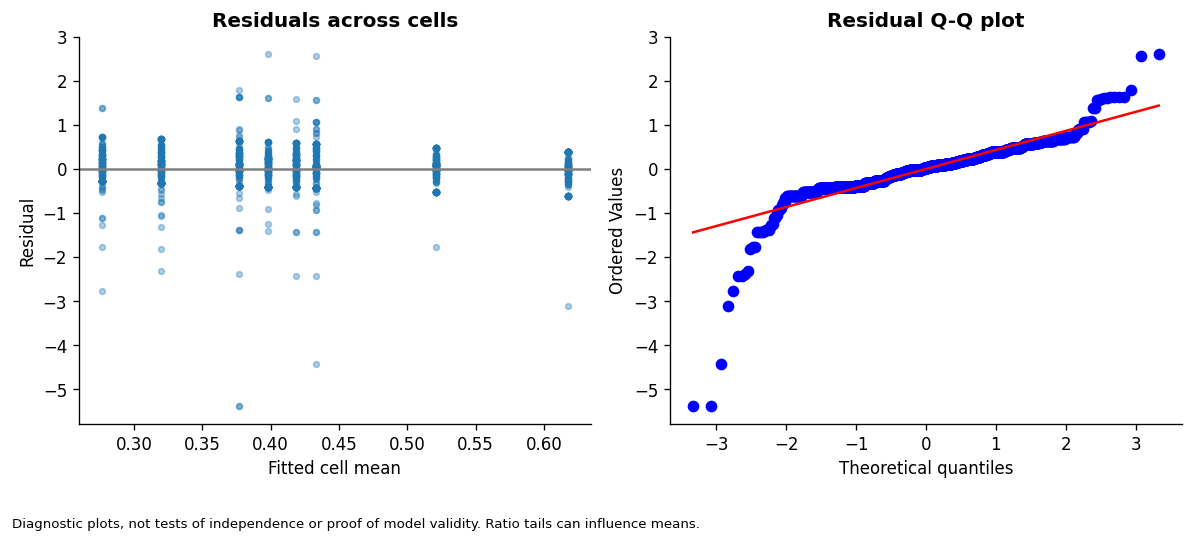

,contrast,difference_in_changes,bootstrap_mean_ci_low,bootstrap_mean_ci_high,difference_in_median_changes,bootstrap_median_ci_low,bootstrap_median_ci_high
0,R3-R1,-0.053075,-0.155136,0.047407,0.048810,-0.109538,0.161111
1,R4-R1,-0.040249,-0.183592,0.111538,0.012121,-0.157495,0.142857
2,R4-R3,0.012826,-0.135225,0.172484,-0.036688,-0.191919,0.121212


,contrast,n_code_1,n_code_0,mean_change_code_1,mean_change_code_0,difference_in_paired_changes,ci_low,ci_high,t,df,p_raw,hedges_g_change,p_holm_secondary_family
0,R3-R1,192,191,-0.291041,-0.248759,-0.042282,-0.148798,0.064235,-0.780516,376.334544,0.435578,-0.079584,1.0
1,R4-R1,195,193,-0.172298,-0.147146,-0.025152,-0.177577,0.127274,-0.324453,377.638288,0.745775,-0.032903,1.0
2,R4-R3,195,196,0.132210,0.097396,0.034814,-0.114764,0.184391,0.457670,371.410061,0.647457,0.046175,1.0


,record_id,shift_R3_R1,shift_R4_R1,shift_R4_R3,max_abs_shift
303,304,-0.000406,-0.027919,-0.027514,0.027919
333,334,-0.000677,-0.027154,-0.026477,0.027154
86,87,-0.000593,0.021462,0.022055,0.022055
94,95,-0.017099,-0.017736,-0.000637,0.017736
283,284,-0.016398,0.000656,0.017054,0.017054
17,18,0.009105,-0.005396,-0.014501,0.014501
194,195,0.001024,-0.013364,-0.014388,0.014388
236,237,-0.001549,-0.013419,-0.011870,0.013419
67,68,-0.004027,0.008987,0.013013,0.013013
42,43,0.011630,-0.000229,-0.011859,0.011859


In [9]:
diagnostic=primary_data[['record_id','condition','round','gap','recalculated']].copy()
diagnostic['residual']=primary_model.resid
diagnostic['fitted']=primary_model.fittedvalues
display(save_table(diagnostic.groupby(['condition','round']).agg(n=('residual','size'),
     residual_sd=('residual','std'),max_absolute_residual=('residual',lambda s:np.abs(s).max()),
     median_absolute_gap=('gap',lambda s:np.abs(s).median())).reset_index(),'model_diagnostics'))
fig,axes=plt.subplots(1,2,figsize=(10,4.5))
axes[0].scatter(diagnostic.fitted,diagnostic.residual,alpha=.35,s=12);axes[0].axhline(0,color='gray')
axes[0].set(xlabel='Fitted cell mean',ylabel='Residual',title='Residuals across cells')
stats.probplot(diagnostic.residual,dist='norm',plot=axes[1]);axes[1].set_title('Residual Q-Q plot')
finish_figure(fig,'06_model_diagnostics','Diagnostic plots, not tests of independence or proof of model validity. Ratio tails can influence means.')
wide=long.pivot(index='record_id',columns='round',values='recalculated').reindex(columns=[1,2,3,4])
codes=analysis.set_index('record_id').Condition.reindex(wide.index)
rng=np.random.default_rng(SEED)
boot_mean=[];boot_median=[]
arrays={g:wide.loc[codes.eq(g)].to_numpy() for g in [0,1]}
for _ in range(BOOTSTRAPS):
    sampled={g:arrays[g][rng.integers(0,len(arrays[g]),len(arrays[g]))] for g in [0,1]}
    means={g:np.nanmean(sampled[g],axis=0) for g in [0,1]}
    medians={g:np.nanmedian(sampled[g],axis=0) for g in [0,1]}
    boot_mean.append([(means[1][a-1]-means[1][b-1])-(means[0][a-1]-means[0][b-1]) for a,b in PLANNED])
    boot_median.append([(medians[1][a-1]-medians[1][b-1])-(medians[0][a-1]-medians[0][b-1]) for a,b in PLANNED])
bootstrap=primary[['contrast','difference_in_changes']].copy()
bootstrap[['bootstrap_mean_ci_low','bootstrap_mean_ci_high']]=np.quantile(boot_mean,[.025,.975],axis=0).T
bootstrap['difference_in_median_changes']=[(np.nanmedian(arrays[1][:,a-1])-np.nanmedian(arrays[1][:,b-1]))-(np.nanmedian(arrays[0][:,a-1])-np.nanmedian(arrays[0][:,b-1])) for a,b in PLANNED]
bootstrap[['bootstrap_median_ci_low','bootstrap_median_ci_high']]=np.quantile(boot_median,[.025,.975],axis=0).T
display(save_table(bootstrap,'record_bootstrap_and_medians'))
paired_rows=[]
for later,earlier in PLANNED:
    change=(wide[later]-wide[earlier])
    x=change[codes.eq(1)].dropna().to_numpy();y=change[codes.eq(0)].dropna().to_numpy()
    test=stats.ttest_ind(x,y,equal_var=False);ci=test.confidence_interval()
    pooled=np.sqrt(((len(x)-1)*np.var(x,ddof=1)+(len(y)-1)*np.var(y,ddof=1))/(len(x)+len(y)-2))
    hedges=(np.mean(x)-np.mean(y))/pooled*(1-3/(4*(len(x)+len(y))-9))
    paired_rows.append({'contrast':f'R{later}-R{earlier}','n_code_1':len(x),'n_code_0':len(y),
                        'mean_change_code_1':x.mean(),'mean_change_code_0':y.mean(),
                        'difference_in_paired_changes':x.mean()-y.mean(),'ci_low':ci.low,'ci_high':ci.high,
                        't':test.statistic,'df':test.df,'p_raw':test.pvalue,'hedges_g_change':hedges})
paired=pd.DataFrame(paired_rows);paired['p_holm_secondary_family']=multipletests(paired.p_raw,method='holm')[1]
display(save_table(paired,'pair_complete_welch_contrasts'))
# Saturated mean estimates can be computed directly, allowing a transparent exact leave-one-record check.
def profile_effect(frame):
    means=frame.groupby(['condition','round']).recalculated.mean()
    return np.array([(means[1,a]-means[1,b])-(means[0,a]-means[0,b]) for a,b in PLANNED])
baseline_effect=profile_effect(long)
influence_rows=[]
for record in analysis.record_id:
    delta=profile_effect(long[long.record_id.ne(record)])-baseline_effect
    influence_rows.append({'record_id':record,**{f'shift_R{a}_R{b}':delta[k] for k,(a,b) in enumerate(PLANNED)},'max_abs_shift':np.abs(delta).max()})
influence=pd.DataFrame(influence_rows).sort_values('max_abs_shift',ascending=False)
display(save_table(influence,'leave_one_record_out_influence').head(10))

## H–I. Trust, literacy and interpretability gates

The documentation identifies response families, while Appendix A provides instrument statements and PT5 reversal. The CSV mapping, response coding implementation, administration timing and reversal status are not established. **No trust, literacy or interpretability composite, subscale, association or moderator is calculated.** Raw response distributions are descriptive and do not establish a common latent score. RQ3 and RQ4 remain blocked; we do not claim that four-round trust recovery is measured. Interpretability could also be post-treatment, precluding automatic causal-covariate interpretation.

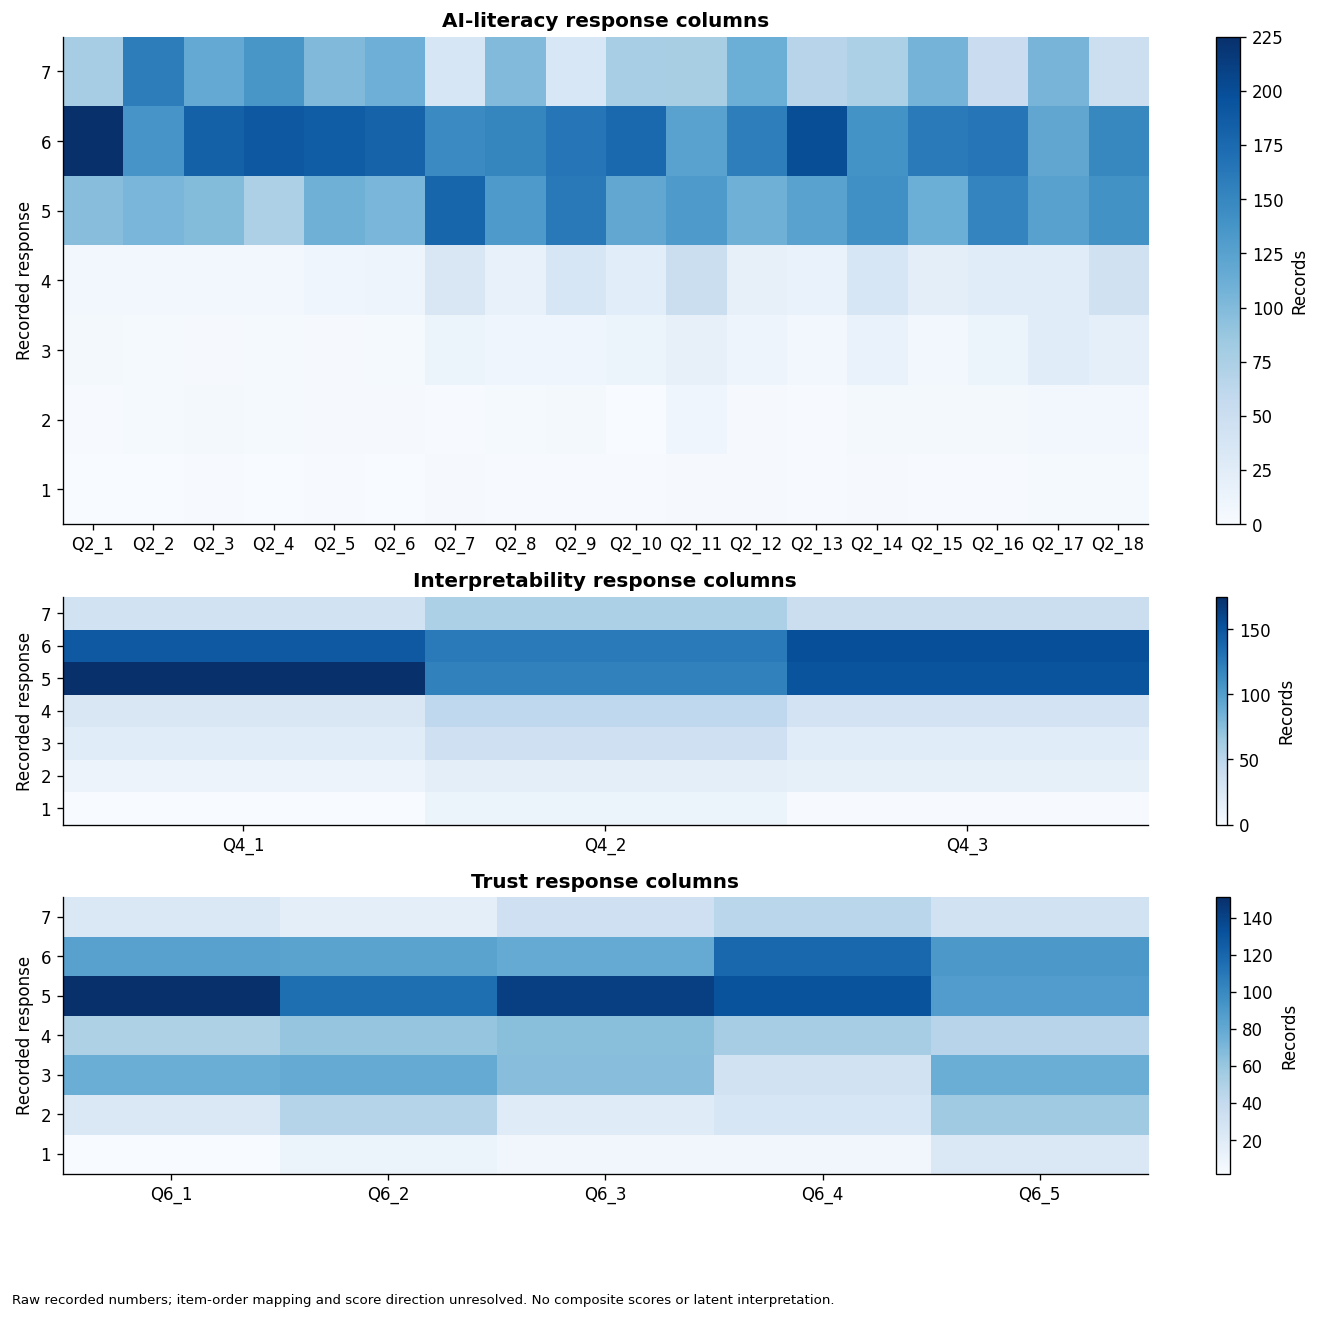

,analysis,status,reason
0,RQ3 trust association,BLOCKED,"CSV-item map, timing, response coding and PT5 ..."
1,RQ4 literacy/interpretability moderation,BLOCKED,Verified composite scoring and item mapping un...
2,Treatment-labelled interpretation,BLOCKED,Numeric condition mapping unavailable
3,Appropriate reliance/accuracy,BLOCKED,Complete round-stimulus true ages unavailable
4,Catalogue alignment,REQUIRES PROFESSOR APPROVAL,Secondary reanalysis replaces the three-interv...


In [10]:
families={'Q2_':'AI-literacy response columns','Q4_':'Interpretability response columns','Q6_':'Trust response columns'}
item_records=[]
fig,axes=plt.subplots(3,1,figsize=(12,11),gridspec_kw={'height_ratios':[3,1.4,1.7]})
for (prefix,title),ax in zip(families.items(),axes):
    cols=[c for c in raw if c.startswith(prefix)]
    count_matrix=np.array([[int(analysis[c].eq(v).sum()) for v in range(1,8)] for c in cols])
    image=ax.imshow(count_matrix.T,aspect='auto',origin='lower',cmap='Blues')
    ax.set(xticks=np.arange(len(cols)),xticklabels=cols,yticks=np.arange(7),yticklabels=range(1,8),ylabel='Recorded response',title=title)
    fig.colorbar(image,ax=ax,label='Records')
    for c in cols:
        for g in [0,1]:
            vals=analysis.loc[analysis.Condition.eq(g),c]
            for v in range(1,8):item_records.append({'column':c,'condition':g,'response':v,'count':int(vals.eq(v).sum()),'n_records':len(vals)})
finish_figure(fig,'07_raw_questionnaire_responses','Raw recorded numbers; item-order mapping and score direction unresolved. No composite scores or latent interpretation.')
save_table(pd.DataFrame(item_records),'raw_item_response_frequencies')
gates=pd.DataFrame([
 {'analysis':'RQ3 trust association','status':'BLOCKED','reason':'CSV-item map, timing, response coding and PT5 export status unresolved'},
 {'analysis':'RQ4 literacy/interpretability moderation','status':'BLOCKED','reason':'Verified composite scoring and item mapping unavailable'},
 {'analysis':'Treatment-labelled interpretation','status':'BLOCKED','reason':'Numeric condition mapping unavailable'},
 {'analysis':'Appropriate reliance/accuracy','status':'BLOCKED','reason':'Complete round-stimulus true ages unavailable'},
 {'analysis':'Catalogue alignment','status':'REQUIRES PROFESSOR APPROVAL','reason':'Secondary reanalysis replaces the three-intervention experiment'}])
display(save_table(gates,'blocked_analysis_register'))

## J. Robustness and measurement sensitivity

The published-export scenario reproduces numeric exported values as a diagnostic only: it includes some invalid zeros. The published-masked scenario changes only undefined-value handling. Recalculated scenarios use the paper formula. Complete cases use all four nonzero denominators, ensuring comparable published/derived record selection. The duplicate sensitivity removes only the later exact duplicate. The small-gap sensitivity requires |A−I|≥2 years for a given observation; it changes the target sample and is not a claim that smaller gaps are invalid. No finite observation is excluded because its WoA falls outside [0,1].

Scenario-specific Holm values apply within each three-contrast family; these repeated analyses are sensitivity evidence, not multiple independent confirmations. Compare effect direction, size and uncertainty, rather than selecting the most significant specification.

,scenario,measure,n_records,n_round_observations,records_with_four_observations
0,published_export_available,published_export,412,1624,388
1,published_masked_available,published_masked,412,1606,370
2,derived_available,recalculated,412,1606,370
3,published_masked_complete,published_masked,370,1480,370
4,derived_complete,recalculated,370,1480,370
5,derived_duplicate_excluded,recalculated,411,1602,369
6,derived_gap_at_least_2,recalculated,412,1463,252


,scenario,contrast,difference_in_changes,se,t,df,ci_low,ci_high,p_raw,n_records,n_round_observations,p_holm
0,published_export_available,R3-R1,-0.044374,0.052756,-0.841118,411.0,-0.148080,0.059331,0.400771,412,1624,0.400771
1,published_export_available,R4-R1,-0.281939,0.074861,-3.766168,411.0,-0.429098,-0.134781,0.000190,412,1624,0.000570
2,published_export_available,R4-R3,-0.237565,0.079876,-2.974163,411.0,-0.394582,-0.080548,0.003111,412,1624,0.006222
3,published_masked_available,R3-R1,-0.053075,0.052966,-1.002051,411.0,-0.157193,0.051044,0.316909,412,1606,0.316909
4,published_masked_available,R4-R1,-0.291600,0.075305,-3.872264,411.0,-0.439630,-0.143569,0.000125,412,1606,0.000376
5,published_masked_available,R4-R3,-0.238525,0.080627,-2.958388,411.0,-0.397017,-0.080033,0.003271,412,1606,0.006542
6,derived_available,R3-R1,-0.053075,0.052966,-1.002051,411.0,-0.157193,0.051044,0.316909,412,1606,0.950726
7,derived_available,R4-R1,-0.040249,0.075288,-0.534601,411.0,-0.188248,0.107749,0.593215,412,1606,1.000000
8,derived_available,R4-R3,0.012826,0.078064,0.164296,411.0,-0.140629,0.166280,0.869579,412,1606,1.000000
9,published_masked_complete,R3-R1,-0.026088,0.055212,-0.472509,369.0,-0.134657,0.082481,0.636843,370,1480,0.636843


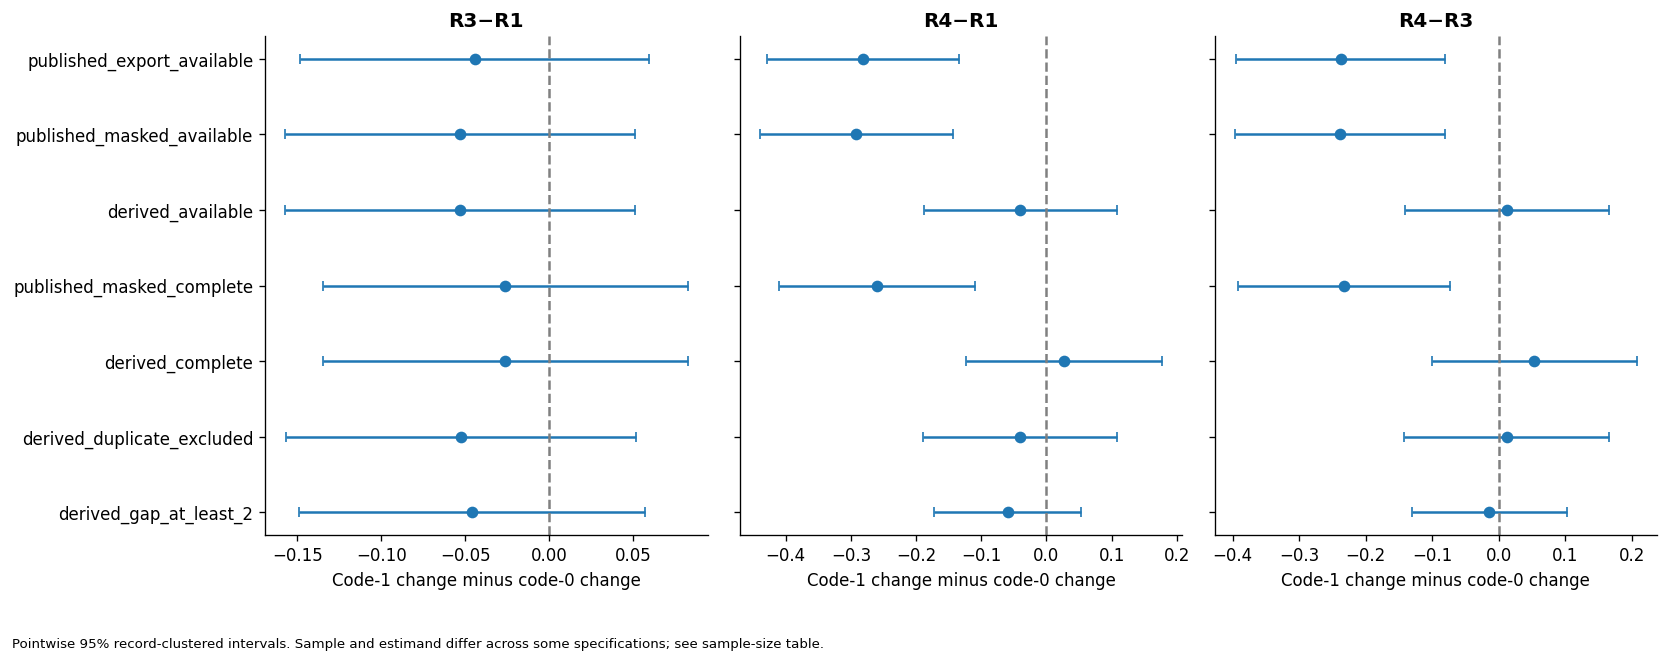

,contrast,estimate,se,ci_low,ci_high,z,p_raw,converged,usable_sensitivity,p_holm_sensitivity
0,R3-R1,-0.053571,0.065972,-0.182875,0.075732,-0.812030,0.416774,True,True,1.0
1,R4-R1,-0.039594,0.065756,-0.168473,0.089285,-0.602142,0.547080,True,True,1.0
2,R4-R3,0.013977,0.065623,-0.114642,0.142597,0.212990,0.831334,True,True,1.0


{'status': 'converged and covariance checks passed',
 'warnings': [],
 'record_intercept_variance': 0.015848081921839893,
 'residual_variance': 0.21577435121403515}

In [11]:
complete_ids=long.groupby('record_id').undefined.sum().loc[lambda s:s.eq(0)].index
scenarios={
 'published_export_available':(long,'published_export'),
 'published_masked_available':(long,'published_masked'),
 'derived_available':(long,'recalculated'),
 'published_masked_complete':(long[long.record_id.isin(complete_ids)],'published_masked'),
 'derived_complete':(long[long.record_id.isin(complete_ids)],'recalculated'),
 'derived_duplicate_excluded':(long[~long.duplicate_extra],'recalculated'),
 'derived_gap_at_least_2':(long[long.gap.abs().ge(SMALL_GAP)],'recalculated')}
sensitivity_parts=[];scenario_sizes=[]
for name,(frame,measure) in scenarios.items():
    fit,table,used=fit_marginal(frame,measure,name)
    sensitivity_parts.append(table)
    scenario_sizes.append({'scenario':name,'measure':measure,'n_records':used.record_id.nunique(),
                           'n_round_observations':len(used),'records_with_four_observations':int(used.groupby('record_id').size().eq(4).sum())})
sensitivity=pd.concat(sensitivity_parts,ignore_index=True)
display(save_table(pd.DataFrame(scenario_sizes),'sensitivity_sample_sizes'))
display(save_table(sensitivity,'sensitivity_contrasts'))
fig,axes=plt.subplots(1,3,figsize=(14,5.5),sharey=True)
names=list(scenarios)
for ax,(a,b) in zip(axes,PLANNED):
    s=sensitivity[sensitivity.contrast.eq(f'R{a}-R{b}')].set_index('scenario').loc[names]
    ax.errorbar(s.difference_in_changes,np.arange(len(names)),xerr=[s.difference_in_changes-s.ci_low,s.ci_high-s.difference_in_changes],fmt='o',capsize=3)
    ax.axvline(0,color='gray',ls='--');ax.set(title=f'R{a}−R{b}',xlabel='Code-1 change minus code-0 change',yticks=np.arange(len(names)),yticklabels=names)
axes[0].invert_yaxis()
finish_figure(fig,'08_sensitivity_contrasts','Pointwise 95% record-clustered intervals. Sample and estimand differ across some specifications; see sample-size table.')
# Alternative covariance specification: random intercept by analytical record, not verified participant.
mixed_warnings=[];mixed_rows=[]
try:
    with warnings.catch_warnings(record=True) as captured:
        warnings.simplefilter('always')
        mixed=sm.MixedLM(primary_data.recalculated.to_numpy(),design_matrix(primary_data),
                         groups=primary_data.record_id.to_numpy()).fit(reml=True,method='powell',maxiter=1000,disp=False)
    mixed_warnings=[str(w.message) for w in captured]
    beta=np.asarray(mixed.fe_params);cov=np.asarray(mixed.cov_params())[:8,:8]
    usable=bool(mixed.converged and np.isfinite(cov).all() and np.linalg.eigvalsh(cov).min()>0 and float(np.asarray(mixed.cov_re).item())>1e-8)
    for a,b in PLANNED:
        v=contrast_vector(a,b);estimate=float(v@beta);se=float(np.sqrt(v@cov@v));z=estimate/se
        mixed_rows.append({'contrast':f'R{a}-R{b}','estimate':estimate,'se':se,
                           'ci_low':estimate-1.959963984540054*se,'ci_high':estimate+1.959963984540054*se,
                           'z':z,'p_raw':2*stats.norm.sf(abs(z)),'converged':bool(mixed.converged),'usable_sensitivity':usable})
    mixed_table=pd.DataFrame(mixed_rows);mixed_table['p_holm_sensitivity']=multipletests(mixed_table.p_raw,method='holm')[1]
    display(save_table(mixed_table,'random_intercept_sensitivity'))
    mixed_status={'status':'converged and covariance checks passed' if usable else 'diagnostically invalid; not used as evidence','warnings':mixed_warnings,
                  'record_intercept_variance':float(np.asarray(mixed.cov_re).item()),'residual_variance':float(mixed.scale)}
except Exception as exc:
    mixed_status={'status':'failed; not used as evidence','error':repr(exc),'warnings':mixed_warnings}
(OUTPUT/'mixed_model_status.json').write_text(json.dumps(mixed_status,indent=2))
display(mixed_status)

## K. Accuracy gate and source discrepancies

There is no complete ground-truth column or stimulus identifier in the supplied CSV. Ouyang Fig. 2 illustrates one true age, but it cannot establish all four round mappings. **No absolute errors, accuracy gains, appropriate-reliance classifications or merges to unrelated images are calculated.** The source Methods identify Round 2 as the deliberate error; one Results passage calls Round 3 the error round. Trust timing and numeric condition mapping also remain unresolved. Requests for clarification have not been sent.

The paper reports interpretability means of 3.34 and 4.12 (printed p. 10). The source audit found that these values do not match ordinary averaging of the apparent Q4 columns; that mapping is unverified. This notebook does not adopt that aggregate or adjust the data to make the paper's values match. Original scoring syntax, condition codebook, stimulus key and exact analysis-file version are needed.

## L–M. Executed results, interpretation and conclusion

The following narrative is generated from the executed tables. It distinguishes the published export from our independently derived variables. Statistical significance is not evidence of causality, unique-participant verification, or successful trust calibration. Questionnaire and accuracy questions are explicitly left unanswered rather than filled with assumptions.

In [12]:
def fnum(x): return f'{x:.4f}'
def pnum(x): return f'{x:.4g}'
report=[]
report.append('# Research Findings and Interpretation')
report.append(f'Actual empirical file: `{DATA_PATH.name}`, SHA256 `{SOURCE_SHA256}`. Observed {len(raw)} records and {len(raw.columns)} columns; no synthetic observations. Numeric codes: '+str(analysis.Condition.value_counts().sort_index().to_dict())+'.')
report.append(f'The primary model used {primary_data.record_id.nunique()} record clusters and {len(primary_data)} finite round observations. The four-round complete-case sample contains {len(complete_ids)} records. These are record counts, not independently verified unique people.')
report.append('## RQ1: measurement sensitivity')
report.append(f'Code 0, Round 4 has {int(r4_comparable.discrepancy.sum())} disagreements among {len(r4_comparable)} comparable values; {int(r4_comparable.complement_match.sum())} match the complement of the paper formula. On these same records the published mean is {r4_comparable.published_export.mean():.4f}, versus {r4_comparable.recalculated.mean():.4f} independently derived. This is inconsistent with the stated formula, but its production cause is unknown.')
for contrast in primary.contrast:
    s=sensitivity[sensitivity.contrast.eq(contrast)].set_index('scenario')
    pub=s.loc['published_masked_available'];der=s.loc['derived_available']
    report.append(f'{contrast}: denominator-masked published estimate {pub.difference_in_changes:.4f}; derived estimate {der.difference_in_changes:.4f}. '+
                  ('The estimated direction reverses.' if np.sign(pub.difference_in_changes)!=np.sign(der.difference_in_changes) else 'The estimated direction is unchanged.')+
                  ' These estimates compare code-1 change minus code-0 change.')
report.append('## RQ2: consistently derived reliance trajectories')
for g in [0,1]:
    s=descriptives[(descriptives.measure=='recalculated')&(descriptives.condition==g)].sort_values('round')
    report.append(f'Condition {g} derived means by round: '+', '.join(f'R{int(x.round)}={x.mean:.4f}' for x in s.itertuples())+'. These are available-observation summaries, not paired changes.')
for row in primary.itertuples():
    report.append(f'{row.contrast}: difference in changes {row.difference_in_changes:.4f} WoA units, pointwise 95% CI [{row.ci_low:.4f}, {row.ci_high:.4f}], t({row.df:.0f})={row.t:.3f}, raw p={pnum(row.p_raw)}, Holm p={pnum(row.p_holm)}. '+
                  ('This meets the .05 Holm criterion.' if row.p_holm<.05 else 'This does not meet the .05 Holm criterion; it is not proof of no difference.'))
report.append('These are available-observation mean-profile differences, conditional on independent records and the missingness pattern. The primary uncertainty intervals are not simultaneous. The secondary pair-complete Welch table instead compares average within-record changes, reporting Hedges g for the change distributions.')
report.append('Within-code round changes are reported in a secondary six-test Holm family in within_code_round_contrasts.csv. The omnibus interaction is secondary and is not used to select the planned contrasts.')
report.append('## Robustness')
for name in ['derived_complete','derived_duplicate_excluded','derived_gap_at_least_2']:
    s=sensitivity[sensitivity.scenario.eq(name)]
    desc='; '.join(f'{x.contrast}: {x.difference_in_changes:.4f} (Holm p={pnum(x.p_holm)})' for x in s.itertuples())
    report.append(f'{name}: {desc}.')
report.append(f'The greatest absolute leave-one-record-out shift across primary contrasts was {influence.max_abs_shift.max():.4f} WoA units. Bootstrap intervals and median contrasts are exported. Random-intercept sensitivity status: {mixed_status["status"]}. Model warnings are retained in mixed_model_status.json.')
report.append('## RQ3 and RQ4')
report.append('Not tested. Composite scoring, item mappings, administration timing and PT5 export reversal are unresolved. Raw-item plots are descriptions of recorded responses only. No moderation power claim is made for an unestimated, unvalidated composite model.')
report.append('## Comparison with earlier research')
report.append('Ouyang et al. (2026), printed pp. 11–13, reported a condition-by-round interaction and greater baseline reliance in Round 4. Our numeric-code comparison cannot be treatment-labelled. The exported late-round pattern is materially sensitive to the paper-defined formula. This is a reproducibility concern, not proof that the original authors used this exact erroneous export or that their entire analysis is false. Their complete-case count is reproduced, but their analysis input and scoring syntax are unavailable.')
report.append("Graf (2025), pp. 7–11, found dynamic self-reported trust responses to system errors. Our outcome is judgment revision, not Graf's repeated trust instrument. Neither study justifies substituting a trust score for behavior. This notebook cannot estimate the catalogue's three disclosure interventions.")
report.append('## Contribution, limits and next evidence')
report.append('The contribution is a transparent sensitivity audit using real data. Statistical procedures cannot resolve unverified participant uniqueness, condition mapping, item scoring, source-version discrepancies, stimulus-round confounding or missing ground truth. Unmodelled repeat participation across nonidentical rows could invalidate record-level standard errors. The duplicate sensitivity cannot exclude that possibility. Undefined WoA is structural; available-observation and complete-case analyses target selected samples. No causal error effect, appropriate-reliance benefit, trust recovery, confirmed theoretical novelty or publication readiness is claimed.')
report.append('Obtain the numeric condition key, questionnaire/scoring/export syntax, original analysis dataset and code, stimulus identifiers and actual ages, error-round clarification, and relevant ethics/reuse information. Formal professor acceptance of the revised scope remains undocumented. This notebook can be academically reviewed for its executed numerical audit; blocked substantive claims require additional evidence.')
RESULTS_TEXT='\n\n'.join(report)
(OUTPUT/'Research_Findings_and_Interpretation.md').write_text(RESULTS_TEXT,encoding='utf-8')
display(Markdown(RESULTS_TEXT))

# Research Findings and Interpretation

Actual empirical file: `Dataset_TrustCalibration.csv`, SHA256 `0ffa5341b5dec771d2e11169ff3bceb4c43306a83677f32d2f81d3a997ef696d`. Observed 412 records and 50 columns; no synthetic observations. Numeric codes: {0: 206, 1: 206}.

The primary model used 412 record clusters and 1606 finite round observations. The four-round complete-case sample contains 370 records. These are record counts, not independently verified unique people.

## RQ1: measurement sensitivity

Code 0, Round 4 has 173 disagreements among 202 comparable values; 201 match the complement of the paper formula. On these same records the published mean is 0.6282, versus 0.3768 independently derived. This is inconsistent with the stated formula, but its production cause is unknown.

R3-R1: denominator-masked published estimate -0.0531; derived estimate -0.0531. The estimated direction is unchanged. These estimates compare code-1 change minus code-0 change.

R4-R1: denominator-masked published estimate -0.2916; derived estimate -0.0402. The estimated direction is unchanged. These estimates compare code-1 change minus code-0 change.

R4-R3: denominator-masked published estimate -0.2385; derived estimate 0.0128. The estimated direction reverses. These estimates compare code-1 change minus code-0 change.

## RQ2: consistently derived reliance trajectories

Condition 0 derived means by round: R1=0.5209, R2=0.3983, R3=0.2767, R4=0.3768. These are available-observation summaries, not paired changes.

Condition 1 derived means by round: R1=0.6174, R2=0.4186, R3=0.3201, R4=0.4330. These are available-observation summaries, not paired changes.

R3-R1: difference in changes -0.0531 WoA units, pointwise 95% CI [-0.1572, 0.0510], t(411)=-1.002, raw p=0.3169, Holm p=0.9507. This does not meet the .05 Holm criterion; it is not proof of no difference.

R4-R1: difference in changes -0.0402 WoA units, pointwise 95% CI [-0.1882, 0.1077], t(411)=-0.535, raw p=0.5932, Holm p=1. This does not meet the .05 Holm criterion; it is not proof of no difference.

R4-R3: difference in changes 0.0128 WoA units, pointwise 95% CI [-0.1406, 0.1663], t(411)=0.164, raw p=0.8696, Holm p=1. This does not meet the .05 Holm criterion; it is not proof of no difference.

These are available-observation mean-profile differences, conditional on independent records and the missingness pattern. The primary uncertainty intervals are not simultaneous. The secondary pair-complete Welch table instead compares average within-record changes, reporting Hedges g for the change distributions.

Within-code round changes are reported in a secondary six-test Holm family in within_code_round_contrasts.csv. The omnibus interaction is secondary and is not used to select the planned contrasts.

## Robustness

derived_complete: R3-R1: -0.0261 (Holm p=1); R4-R1: 0.0275 (Holm p=1); R4-R3: 0.0536 (Holm p=1).

derived_duplicate_excluded: R3-R1: -0.0525 (Holm p=0.9715); R4-R1: -0.0407 (Holm p=1); R4-R3: 0.0118 (Holm p=1).

derived_gap_at_least_2: R3-R1: -0.0457 (Holm p=0.8993); R4-R1: -0.0596 (Holm p=0.8993); R4-R3: -0.0139 (Holm p=0.8993).

The greatest absolute leave-one-record-out shift across primary contrasts was 0.0279 WoA units. Bootstrap intervals and median contrasts are exported. Random-intercept sensitivity status: converged and covariance checks passed. Model warnings are retained in mixed_model_status.json.

## RQ3 and RQ4

Not tested. Composite scoring, item mappings, administration timing and PT5 export reversal are unresolved. Raw-item plots are descriptions of recorded responses only. No moderation power claim is made for an unestimated, unvalidated composite model.

## Comparison with earlier research

Ouyang et al. (2026), printed pp. 11–13, reported a condition-by-round interaction and greater baseline reliance in Round 4. Our numeric-code comparison cannot be treatment-labelled. The exported late-round pattern is materially sensitive to the paper-defined formula. This is a reproducibility concern, not proof that the original authors used this exact erroneous export or that their entire analysis is false. Their complete-case count is reproduced, but their analysis input and scoring syntax are unavailable.

Graf (2025), pp. 7–11, found dynamic self-reported trust responses to system errors. Our outcome is judgment revision, not Graf's repeated trust instrument. Neither study justifies substituting a trust score for behavior. This notebook cannot estimate the catalogue's three disclosure interventions.

## Contribution, limits and next evidence

The contribution is a transparent sensitivity audit using real data. Statistical procedures cannot resolve unverified participant uniqueness, condition mapping, item scoring, source-version discrepancies, stimulus-round confounding or missing ground truth. Unmodelled repeat participation across nonidentical rows could invalidate record-level standard errors. The duplicate sensitivity cannot exclude that possibility. Undefined WoA is structural; available-observation and complete-case analyses target selected samples. No causal error effect, appropriate-reliance benefit, trust recovery, confirmed theoretical novelty or publication readiness is claimed.

Obtain the numeric condition key, questionnaire/scoring/export syntax, original analysis dataset and code, stimulus identifiers and actual ages, error-round clarification, and relevant ethics/reuse information. Formal professor acceptance of the revised scope remains undocumented. This notebook can be academically reviewed for its executed numerical audit; blocked substantive claims require additional evidence.

## N. Integrity checks, reports and reproducibility manifest

Checks verify the implemented formula, source preservation, analysis counts, primary estimates against direct cell means, and consistency of hypothesis adjustment. Reports and figures are regenerated on each run. Resampling uses a fixed seed; timestamp and absolute execution path may change. The delivered project ZIP also contains this executed notebook, the unchanged CSV and a portable execution helper. Full execution success means numerical reproducibility under these assumptions, not publication readiness.

In [13]:
checks={}
checks['raw_dataframe_preserved']=raw.equals(source_snapshot)
checks['source_file_checksum_unchanged']=sha256(DATA_PATH)==SOURCE_SHA256
checks['four_rounds_per_source_record']=bool(long.groupby('record_id')['round'].nunique().eq(4).all())
checks['all_undefined_ratios_missing']=bool(long.loc[long.undefined,'recalculated'].isna().all())
finite=long.recalculated.notna()
checks['formula_reconstructs_final_judgments']=bool(np.allclose(long.loc[finite,'initial']+long.loc[finite,'gap']*long.loc[finite,'recalculated'],long.loc[finite,'final']))
checks['finite_unclipped_ratios_retained']=int(finite.sum())==int(long.gap.ne(0).sum())
checks['complete_case_count_matches_observed_filter']=len(complete_ids)==int(wide.notna().all(axis=1).sum())
checks['primary_matches_direct_cell_mean_contrasts']=bool(np.allclose(primary.difference_in_changes,profile_effect(long)))
checks['holm_probabilities_valid']=bool(primary.p_holm.between(0,1).all() and (primary.p_holm>=primary.p_raw-1e-12).all())
checks['primary_sample_count_matches_table']=bool(primary.n_round_observations.eq(len(primary_data)).all())
if not all(checks.values()):raise AssertionError(checks)
display(pd.Series(checks,name='passed').to_frame())
quality_report=(f'# Data Quality and Reproducibility Report\n\nSource checksum: `{SOURCE_SHA256}`.\n\n'
 f'Observed shape: {raw.shape}. Numeric codes: {analysis.Condition.value_counts().sort_index().to_dict()}. '
 f'No participant ID; {int(duplicate_flags.sum())} extra exact duplicate row(s), retained in primary analysis. '
 f'Duplicate source locators: {duplicate_rows.to_dict(orient="records")}.\n\n'
 '## Source column quality\n\n'+md_table(quality)+'\n\n## WoA audit\n\n'+md_table(audit)+
 '\n\n## Interpretation\n\nBlank cells, division-error strings and numeric zeros at zero denominators differ. '
 'Undefined ratios are missing by the original paper rule. Published values are retained separately. '
 'Empty unnamed columns and feedback text are excluded only from the numeric analytical view. '
 'No complete stimulus ground truth, explicit participant identifier or numeric condition codebook exists in the supplied file. '
 'Questionnaire values are within 1–7, but scoring/administration/export coding remain unresolved. '
 'See discrepancy tables for exact source-line references.\n\n## Integrity checks\n\n'+md_table(pd.DataFrame({'check':checks.keys(),'passed':checks.values()})))
(BASE/'Data_Quality_and_Reproducibility_Report.md').write_text(quality_report,encoding='utf-8')
methodology=("""# Research Methodology and Analytical Decisions

This is an executed secondary-data reproducibility audit of the supplied empirical CSV. The original catalogue intervention study is not implemented. Professor acceptance of the revised scope is not documented.

## Record linkage and preprocessing

CSV row ordinals are analytical record keys, not fabricated participant identities. Four rounds are linked only within their existing source row. Independent records are an inferential assumption; unique participants cannot be certified. All raw strings and original files are preserved. Exact duplicates are retained in the primary analysis, with exclusion sensitivity. No imputation, clipping, synthetic replacement data or accuracy proxy is used.

## Estimands and methods

The primary outcome is paper-defined signed WoA=(F-I)/(A-I), missing when A=I. The primary model uses eight saturated numeric-condition-by-round means, with record-clustered sandwich covariance, finite-cluster correction and t/F inference. Three code-1-minus-code-0 differences in changes (R3-R1, R4-R1, R4-R3) form one Holm-adjusted family. Pointwise 95% intervals and raw WoA-unit effects are reported. This is an available-observation mean-profile estimand, not necessarily an average paired change.

Secondary pair-complete Welch tests report differences in within-record change, Welch degrees of freedom, intervals and Hedges g. Their multiplicity family is separate and secondary. Within-code round contrasts have a separate secondary six-test Holm family. A stratified record bootstrap provides mean/median uncertainty. A random-intercept-by-record model is an alternative covariance specification using Powell optimization; convergence, covariance diagnostics and warnings are explicitly recorded. Invalid fits are not treated as evidence.

Sensitivity comparisons isolate exported numeric values, denominator masking, formula recalculation, four-round complete cases, later exact-duplicate removal and absolute advice gaps of at least two years. Small-gap exclusion changes the sample and is not a validated cutoff. No out-of-range finite WoA is excluded merely for being outside 0–1. Residual, ratio-gap and leave-one-record influence diagnostics are exported.

## Blocked analyses and scope

Condition treatment labels, validated questionnaire composites and moderators, and accuracy are blocked. Raw questionnaire responses are shown by column without assuming item wording or score direction. PT5 reversal is documented in Appendix A, but its exported status and column mapping remain unresolved. The figure's single example age is insufficient ground truth for four stimuli. Round changes confound time, stimulus and error history. Missingness is structural, and neither complete-case nor available-observation inference removes that selection limitation.

## Sources

Ouyang, Jahng & Woo (2026), DOI 10.1080/10447318.2026.2705163, printed pp. 6–9 (design, formula, missingness), 10–13 (published analyses), Appendix A p. 19 (questionnaire). Dataset DOI 10.17632/5w56cp2ftr.1, V1, CC BY 4.0: attribute original authors; independently derived analytical columns are modifications, not author corrections. Graf (2025), DOI 10.1016/j.chb.2025.108736, pp. 4–7 and 10–11. UE catalogue: Project 7 and common checkpoints. The preceding research-design audit is documented in the project conversation; a separate audit attachment was not supplied.

## Academic review boundary

This project documents reproducibility and sensitivity, not independent confirmation, new intervention evidence or publication readiness. Required clarifications: numeric codebook, questionnaire scoring/timing/export syntax, original analysis input/code, complete stimulus key/ages, error-round discrepancy, and ethics/reuse documentation. No messages to authors were sent.
""")
(BASE/'Methodology_and_Analytical_Decisions.md').write_text(methodology,encoding='utf-8')
(BASE/'requirements.txt').write_text('\n'.join(f'{name}=={version}' for name,version in packages.items())+'\n')
manifest={'project':'Trust After AI Failure: A Reproducibility and Measurement-Sensitivity Analysis of Behavioural Reliance in Human–AI Interaction','data_path':str(DATA_PATH),'source_sha256':SOURCE_SHA256,
 'source_rows':len(raw),'source_columns':len(raw.columns),'identifier':'CSV data-row ordinal; not verified participant ID',
 'primary_record_clusters':int(primary_data.record_id.nunique()),'primary_round_observations':len(primary_data),
 'complete_case_records':len(complete_ids),'seed':SEED,'bootstrap_replicates':BOOTSTRAPS,'ratio_tolerance':TOL,
 'small_gap_sensitivity_years':SMALL_GAP,'packages':packages,'python':sys.version,'platform':platform.platform(),
 'created_utc':datetime.now(timezone.utc).isoformat(),'checks':checks,'blocked':gates.to_dict(orient='records'),
 'mixed_model_status':mixed_status,'source_license':'Dataset V1 CC BY 4.0; original papers not redistributed',
 'outputs':[str(p.relative_to(BASE)) for p in sorted(OUTPUT.rglob('*')) if p.is_file()],
 'notebook_execution':'All analytical cells reached integrity/export cell; final cell executes next'}
(OUTPUT/'execution_manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')
print('All checks passed. Reports, tables and PNG/PDF figures exported to', BASE)

,passed
raw_dataframe_preserved,True
source_file_checksum_unchanged,True
four_rounds_per_source_record,True
all_undefined_ratios_missing,True
formula_reconstructs_final_judgments,True
finite_unclipped_ratios_retained,True
complete_case_count_matches_observed_filter,True
primary_matches_direct_cell_mean_contrasts,True
holm_probabilities_valid,True
primary_sample_count_matches_table,True


All checks passed. Reports, tables and PNG/PDF figures exported to /Users/keshavreddy/Downloads/Trust_After_AI_Failure


In [14]:
print('Notebook execution completed. Review the generated results and blocked-analysis register before interpreting treatment or psychological mechanisms.')

Notebook execution completed. Review the generated results and blocked-analysis register before interpreting treatment or psychological mechanisms.
